# Telco Customer Churn Prediction

Este projeto tem como objetivo analisar os fatores associados à rotatividade de clientes de uma empresa de telecomunicações e desenvolver modelos de Machine Learning capazes de identificar clientes com maior risco de churn.

O projeto utiliza o conjunto de dados IBM Telco Customer Churn e contempla análise exploratória, tratamento de dados, modelagem e avaliação dos resultados.

## 1. Importação das bibliotecas

In [389]:
import chardet
import joblib
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
  accuracy_score,
  precision_score,
  recall_score,
  f1_score,
  roc_auc_score,
  classification_report,
  ConfusionMatrixDisplay,
  RocCurveDisplay
)

import warnings
warnings.filterwarnings("ignore")

## 2. Carregamento dos dados

Nesta etapa, o conjunto de dados é carregado e uma inspeção inicial é realizada para compreender sua estrutura

In [300]:
file_path ="../data/Telco_customer_churn.xlsx"

with open (file_path, "rb") as f:
  encoding_detect = chardet.detect(f.read())["encoding"]

df = pd.read_excel(file_path)

In [301]:
print(f"Linhas: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

Linhas: 7043
Colunas: 33


In [302]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

In [303]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Count,7043.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
Country,7043,1,United States,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,7043,1,California,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,7043,1129,Los Angeles,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zip Code,7043.0,NaN,NaN,NaN,93521.964646,1865.794555,90001.0,92102.0,93552.0,95351.0,96161.0
Lat Long,7043,1652,"34.159534, -116.425984",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,7043.0,NaN,NaN,NaN,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,NaN,NaN,NaN,-119.79888,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Entendimento incial dos dados

Antes de iniciar o tratamento, serão avaliados valores ausentes, resgitros duplicados, tipos das variáveis e distribuição da variável alvo.

In [304]:
df.isnull().sum().sort_values(ascending=False)

Churn Reason         5174
CustomerID              0
Count                   0
State                   0
Country                 0
Zip Code                0
Lat Long                0
Latitude                0
City                    0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Longitude               0
Internet Service        0
Online Security         0
Device Protection       0
Online Backup           0
Streaming TV            0
Streaming Movies        0
Contract                0
Tech Support            0
Paperless Billing       0
Payment Method          0
Total Charges           0
Monthly Charges         0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
dtype: int64

In [305]:
print(f"Registros Duplicados: {df.duplicated().sum()}")

Registros Duplicados: 0


In [306]:
df.dtypes

CustomerID            object
Count                  int64
Country               object
State                 object
City                  object
Zip Code               int64
Lat Long              object
Latitude             float64
Longitude            float64
Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges         object
Churn Label           object
Churn Value            int64
Churn Score            int64
CLTV                   int64
Churn Reason          object
dtype: object

## 4. Variável Alvo

A variável `churn Value` representa se um cliente deixou ou não a empresa:

- `0`: Cliente permaneceu;
- `1`: Cliente cancelou o serviço.

In [307]:
df["Churn Value"].value_counts()

Churn Value
0    5174
1    1869
Name: count, dtype: int64

In [308]:
df["Churn Value"].value_counts(normalize=True) * 100

Churn Value
0    73.463013
1    26.536987
Name: proportion, dtype: float64

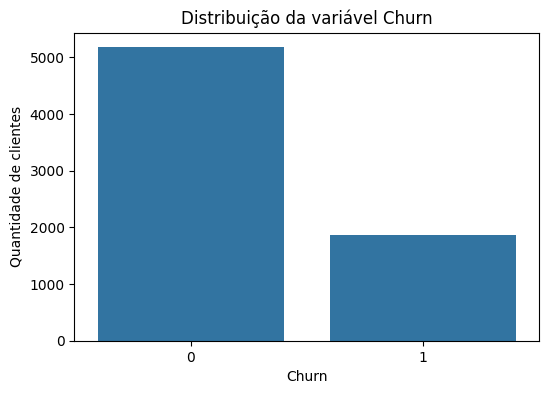

In [309]:
plt.figure(figsize=(6, 4))

sns.countplot(
  data=df,
  x="Churn Value"
)

plt.title("Distribuição da variável Churn")
plt.xlabel("Churn")
plt.ylabel("Quantidade de clientes")

plt.show()

## 5. Remoção de variáveis

Algumas variáveis não devem ser utilizadas durante o treinamento do modelo.

`CustomerID` representa apenas um identificador único do cliente e não possui valor preditivo.

As variáveis `Churn Label`, `Churn Score` e `Churn Reason` também são removidas porque possuem informações diretamente relacionadas ao resultado de churn, o que poderia provocar **data leakage**.

In [310]:
columns_to_drop = [
  "CustomerID",
  "Churn Label",
  "Churn Score",
  "Churn Reason"
]

df = df.drop(columns=columns_to_drop)

df.shape

(7043, 29)

## 6. Tratamento da variável Total Charges

A variável `Total Charges` deveria representar um valor numérico, porém alguns registros podem conter valores inválidos ou espaços em branco.

Esses valores serão convertidos para `Nan` para permitir uma análise mais adequada antes da definição do tratamento.

In [311]:
df["Total Charges"] = pd.to_numeric(
  df["Total Charges"],
  errors="coerce"
)

In [312]:
df["Total Charges"].isnull().sum()

np.int64(11)

In [313]:
df[df["Total Charges"].isnull()]

,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,...,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,CLTV
2234,1,United States,California,San Bernardino,92408,"34.084909, -117.258107",34.084909,-117.258107,Female,No,...,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,0,2578
2438,1,United States,California,Independence,93526,"36.869584, -118.189241",36.869584,-118.189241,Male,No,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,0,5504
2568,1,United States,California,San Mateo,94401,"37.590421, -122.306467",37.590421,-122.306467,Female,No,...,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,0,2048
2667,1,United States,California,Cupertino,95014,"37.306612, -122.080621",37.306612,-122.080621,Male,No,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,0,4950
2856,1,United States,California,Redcrest,95569,"40.363446, -123.835041",40.363446,-123.835041,Female,No,...,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,0,4740
4331,1,United States,California,Los Angeles,90029,"34.089953, -118.294824",34.089953,-118.294824,Male,No,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,0,2019
4687,1,United States,California,Sun City,92585,"33.739412, -117.173334",33.739412,-117.173334,Male,No,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,0,2299
5104,1,United States,California,Ben Lomond,95005,"37.078873, -122.090386",37.078873,-122.090386,Female,No,...,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,0,3763
5719,1,United States,California,La Verne,91750,"34.144703, -117.770299",34.144703,-117.770299,Male,No,...,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,0,4890
6772,1,United States,California,Bell,90201,"33.970343, -118.171368",33.970343,-118.171368,Female,No,...,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,0,2342


In [314]:
missing_total_charges = df[df["Total Charges"].isnull()]

print(f"Quantidade de valores ausentes: {missing_total_charges.shape[0]}")
print(f"Valores de Tenure Months encontrados:", missing_total_charges["Tenure Months"].unique())

Quantidade de valores ausentes: 11
Valores de Tenure Months encontrados: [0]


### Tratamento dos valores ausentes

Após a conversão da variável `Total Charges` para o tipo numérico, foram identificados registros com valores ausentes.

A análise mostrou que esses clientes possuem `Tenure Months = 0`, indicando que ainda não completaram um mês de permanência na empresa. Como ainda não houve tempo para acumular cobranças, os valores ausentes de `Total Charges` serão preenchidos com `0`.

Essa abordagem permite preservar registros válidos sem realizar uma imputação arbitrária ou excluir clientes recém-adquiridas.

In [315]:
df["Total Charges"] = df["Total Charges"].fillna(0)

In [316]:
df["Total Charges"].isnull().sum()

np.int64(0)

## 7. Análise Exploratória de Dados (EDA)

Nesta etapa serão analisadas as principais características dos clientes e sua relação com o churn.

O objetivo é identificar padrões que possam ajudar a compreender quais grupos apresentam maior risco de cancelamento.

In [317]:
churn_distribution = (
  df["Churn Value"]
  .value_counts(normalize=True)
  .mul(100)
  .round(2)
)

churn_distribution

Churn Value
0    73.46
1    26.54
Name: proportion, dtype: float64

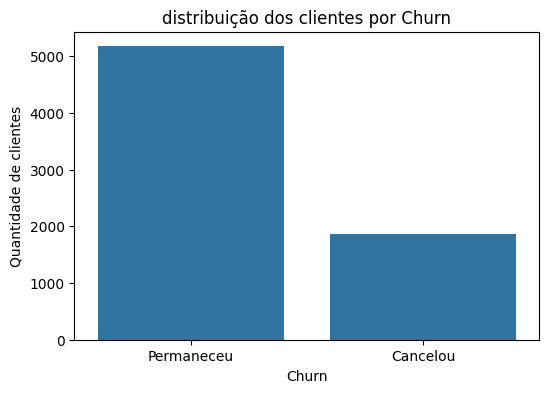

In [318]:
plt.figure(figsize=(6, 4))

ax = sns.countplot(
  data=df,
  x="Churn Value"
)

plt.title("distribuição dos clientes por Churn")
plt.xlabel("Churn")
plt.ylabel("Quantidade de clientes")

plt.xticks(
  ticks=[0, 1],
  labels=["Permaneceu","Cancelou"]
)

plt.show()

### Análise

A distribuição da variável alvo permite avaliar se existe desbalanceamento entre clientes que permaneceram e clientes que cancelaram o serviço.

Essa análise será considerada posteriormente na escolha das métricas de avaliação dos modelos, evitando utilizar apenas a acurácia como medida de desempenho.

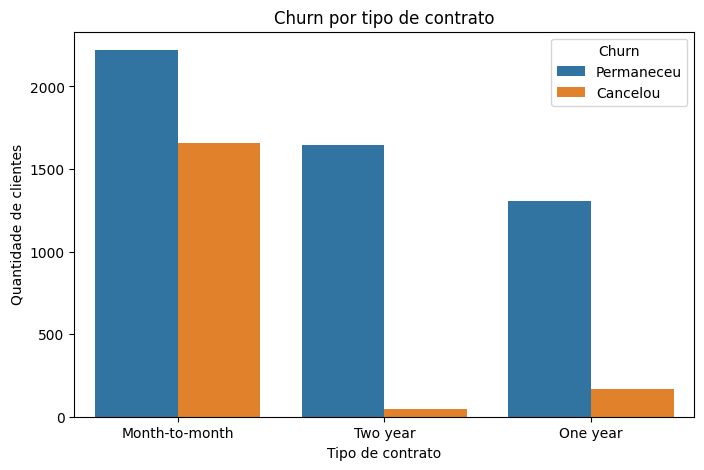

In [319]:
plt.figure(figsize=(8, 5))

sns.countplot(
  data=df,
  x="Contract",
  hue="Churn Value"
)

plt.title("Churn por tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Quantidade de clientes")
plt.legend(
  title="Churn",
  labels=["Permaneceu", "Cancelou"]
)

plt.show()

In [320]:
contract_churn = pd.crosstab(
  df["Contract"],
  df["Churn Value"],
  normalize="index"
).mul(100).round(2)

contract_churn

Churn Value,0,1
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


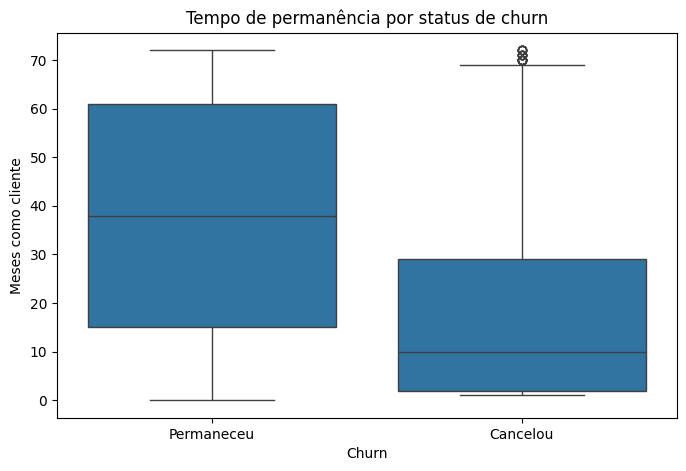

In [321]:
plt.figure(figsize=(8, 5))

sns.boxplot(
  data=df,
  x="Churn Value",
  y="Tenure Months"
)

plt.title("Tempo de permanência por status de churn")
plt.xlabel("Churn")
plt.ylabel("Meses como cliente")

plt.xticks(
  ticks=[0, 1],
  labels=["Permaneceu", "Cancelou"]
)

plt.show()

In [322]:
df.groupby("Churn Value")["Tenure Months"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Churn Value,,,,,,,,
0,5174.0,37.57,24.11,0.0,15.0,38.0,61.0,72.0
1,1869.0,17.98,19.53,1.0,2.0,10.0,29.0,72.0


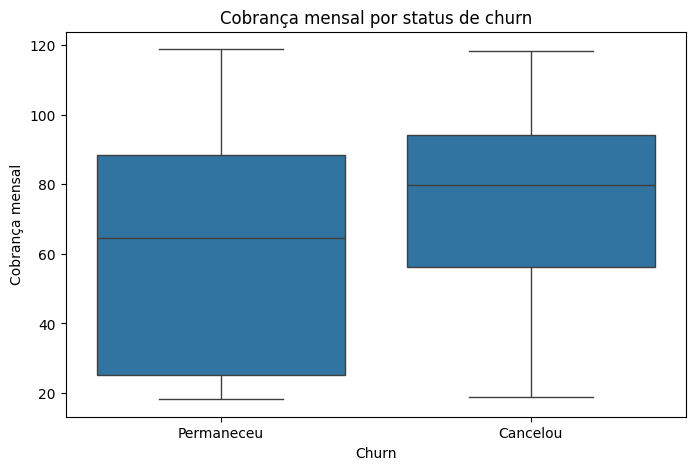

In [323]:
plt.figure(figsize=(8, 5))

sns.boxplot(
  data=df,
  x="Churn Value",
  y="Monthly Charges"
)

plt.title("Cobrança mensal por status de churn")
plt.xlabel("Churn")
plt.ylabel("Cobrança mensal")

plt.xticks(
  ticks=[0, 1],
  labels=["Permaneceu", "Cancelou"]
)

plt.show()

In [324]:
df.groupby("Churn Value")["Monthly Charges"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
Churn Value,,,,,,,,
0,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
1,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35


### Principais observações

A análise exploratória revelou padrões importantes associados ao churn.

#### Tipo de contrato

Clientes com contrato **Month-to-month** apresentam uma taxa de churn de **42,71%**, consideravelmente superior aos clientes com contratos de **One year (11,27%)** e **Two year (2,83%)**.

Esse resultado indica que contratos de menor duração estão fortemente associados a uma maior probabilidade de cancelamento.

#### Tempo de permanência

Clientes que permaneceram na empresa possuem, em média, **37,57 meses** de relacionamento, enquanto clientes que cancelaram apresentam média de apenas **17,98 meses**.

A mediana também apresenta diferença significativa:

- clientes que permaneceram: **38 meses**;
- clientes que cancelaram: **10 meses**.

Isso sugere que o risco de churn é maior entre clientes com menor tempo de relacionamento com a empresa.

#### Cobrança mensal

Clientes que cancelaram possuem cobrança mensal média de **74,44**, enquanto os clientes que permaneceram apresentam média de **61,27**.

A mediana também é superior entre os clientes que cancelaram:

- permaneceu: **64,43**;
- cancelou: **79,65**.

Esse comportamento indica que valores mensais mais elevados podem estar associados a uma maior propensão ao churn.

### Síntese

Os resultados iniciais sugerem que clientes com:

- contratos mensais;
- menor tempo de permanência;
- cobranças mensais mais elevadas;

formam grupos com maior incidência de churn.

Essas variáveis poderão apresentar relevância durante a etapa de modelagem preditiva.

In [325]:
def churn_rate_by_category(data, column):
  churn_rate = pd.crosstab(
    data[column],
    data["Churn Value"],
    normalize="index"
  ).mul(100).round(2)

  return churn_rate

In [326]:
churn_rate_by_category(df, "Internet Service")

Churn Value,0,1
Internet Service,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [327]:
churn_rate_by_category(df, "Payment Method")

Churn Value,0,1
Payment Method,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


In [328]:
churn_rate_by_category(df, "Tech Support")

Churn Value,0,1
Tech Support,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


In [329]:
churn_rate_by_category(df, "Online Security")

Churn Value,0,1
Online Security,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


In [330]:
def plot_churn_by_category(data, column, title, xlabel):
  plt.figure(figsize=(9,5))

  sns.countplot(
    data=data,
    x=column,
    hue="Churn Value"
  )

  plt.title(title)
  plt.xlabel(xlabel)
  plt.ylabel("Quantidade de clientes")

  plt.legend(
    title="Churn",
    labels=["Permaneceu", "Cancelou"]
  )

  plt.xticks(rotation=20)
  plt.tight_layout()
  plt.show()

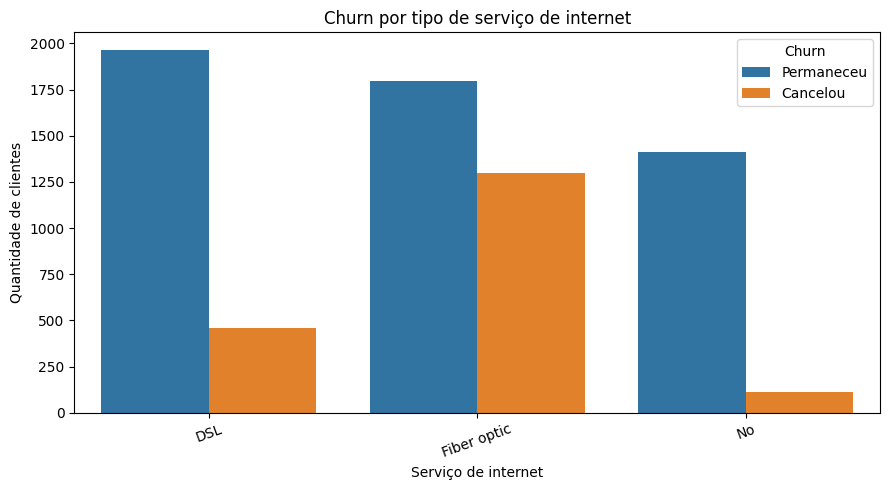

In [331]:
plot_churn_by_category(df, "Internet Service", "Churn por tipo de serviço de internet", "Serviço de internet")

In [332]:
churn_rate_by_category(df, "Internet Service")

Churn Value,0,1
Internet Service,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


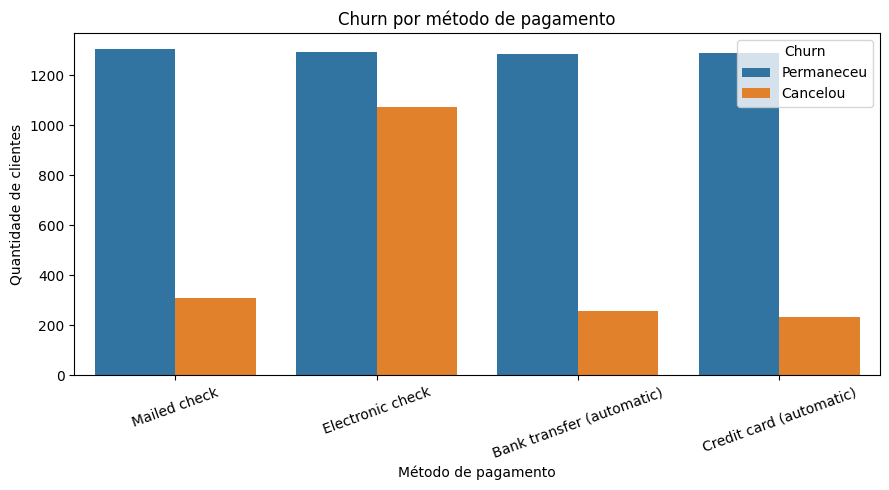

In [333]:
plot_churn_by_category(df, "Payment Method", "Churn por método de pagamento", "Método de pagamento")

In [334]:
churn_rate_by_category(df, "Payment Method")

Churn Value,0,1
Payment Method,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


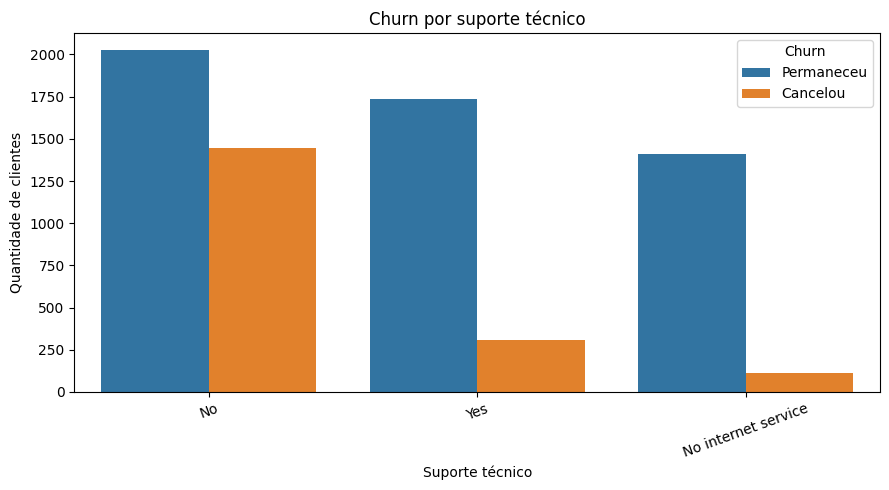

In [335]:
plot_churn_by_category(df, "Tech Support", "Churn por suporte técnico", "Suporte técnico")

In [336]:
churn_rate_by_category(df, "Tech Support")

Churn Value,0,1
Tech Support,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


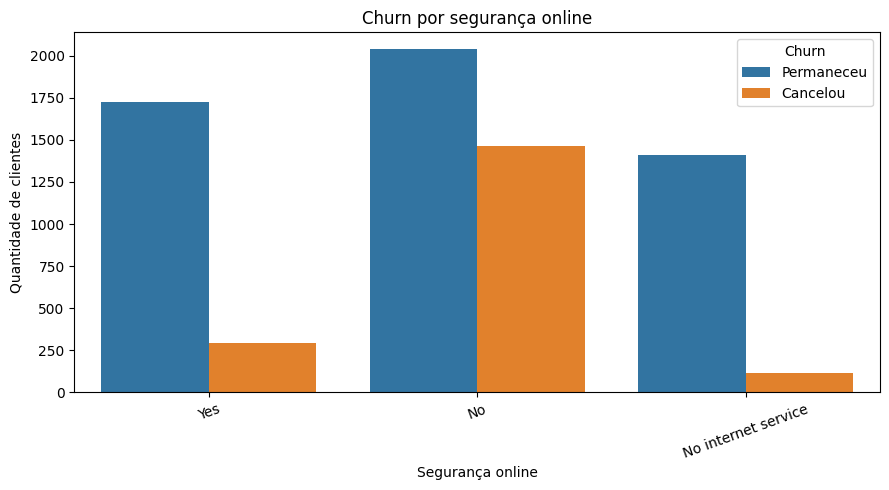

In [337]:
plot_churn_by_category(df, "Online Security", "Churn por segurança online", "Segurança online")

In [338]:
churn_rate_by_category(df,"Online Security")

Churn Value,0,1
Online Security,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


### Análise dos serviços e métodos de pagamento

A análise das variáveis categóricas revelou diferenças relevantes nas taxas de churn entre diferentes grupos de clientes.

#### Serviço de internet

Clientes que utilizam **Fiber optic** apresentam taxa de churn de **41,89%**, enquanto clientes com **DSL** apresentam taxa de **18,96%**.

Clientes sem serviço de internet apresentam a menor taxa de churn, com **7,40%**.

Esse resultado sugere que clientes de fibra óptica apresentam uma incidência de cancelamento significativamente maior.

#### Método de pagamento

O método **Electronic check** apresenta a maior taxa de churn, com **45,29%**.

Os demais métodos apresentam taxas consideravelmente menores:

- Bank transfer (automatic): **16,71%**
- Credit card (automatic): **15,24%**
- Mailed check: **19,11%**

Esse padrão indica uma forte associação entre o uso de cheque eletrônico e maior incidência de cancelamento.

#### Suporte técnico

Clientes que não possuem **Tech Support** apresentam taxa de churn de **41,64%**, enquanto clientes que utilizam o serviço apresentam taxa de **15,17%**.

Isso sugere que a disponibilidade de suporte técnico pode estar associada a uma maior retenção de clientes.

#### Segurança online

Clientes sem **Online Security** apresentam taxa de churn de **41,77%**, enquanto clientes que possuem o serviço apresentam taxa de apenas **14,61%**.

Assim como observado no suporte técnico, a presença de serviços adicionais de suporte e proteção está associada a taxas menores de cancelamento.

## 8. Principais conclusões da análise exploratória

A análise exploratória identificou diversos padrões associados ao churn.

Os grupos com maior incidência de cancelamento foram:

- clientes com contrato **Month-to-month**, com churn de **42,71%**;
- clientes com menor tempo de permanência na empresa;
- clientes com cobranças mensais mais elevadas;
- clientes que utilizam **Fiber optic**, com churn de **41,89%**;
- clientes que utilizam **Electronic check**, com churn de **45,29%**;
- clientes sem **Tech Support**, com churn de **41,64%**;
- clientes sem **Online Security**, com churn de **41,77%**.

Por outro lado, contratos de maior duração apresentaram taxas significativamente menores de cancelamento. Clientes com contrato de dois anos, por exemplo, apresentaram apenas **2,83% de churn**.

Esses resultados sugerem que fatores relacionados ao tipo de contrato, tempo de relacionamento, preço, método de pagamento e serviços adicionais podem desempenhar um papel importante na probabilidade de cancelamento.

Na próxima etapa, essas variáveis serão preparadas para o treinamento dos modelos de Machine Learning.

## 9. Preparação dos dados para Machine Learning

Nesta etapa, as variáveis preditoras serão separadas da variável alvo.

Posteriormente, os dados serão divididos entre conjuntos de treino e teste antes da aplicação das transformações, evitando vazamento de informações entre os conjuntos.

### Seleção inicial de variáveis

Antes da modelagem, algumas variáveis foram removidas por não representarem características adequadas para o objetivo preditivo deste projeto.

Foram excluídas variáveis geográficas de alta granularidade, como cidade, CEP, latitude e longitude, além de campos auxiliares como `Count`.

A variável `CLTV` também foi retirada desta primeira abordagem para que o modelo seja construído principalmente a partir de características diretamente relacionadas ao perfil, serviços contratados, relacionamento e cobrança do cliente.

Essa seleção busca reduzir complexidade, evitar dependência excessiva de informações específicas da base e facilitar a interpretação do modelo.

In [339]:
columns_to_remove = [
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
    "CLTV",
]

X = df.drop(columns=["Churn Value"] + columns_to_remove)

y = df["Churn Value"]

print("Dimensão das features:", X.shape)
print("Dimensão do target:", y.shape)

Dimensão das features: (7043, 19)
Dimensão do target: (7043,)


In [340]:
y.value_counts(normalize=True).mul(100).round(2)

Churn Value
0    73.46
1    26.54
Name: proportion, dtype: float64

In [341]:
X_train, X_test, y_train, y_test = train_test_split(
  X,
  y,
  test_size=0.20,
  random_state=42,
  stratify=y
)

In [342]:
numeric_features = X_train.select_dtypes(
  include=["number"]
).columns

categorical_features = X_train.select_dtypes(
  exclude=["number"]
).columns

print("Variáveis numéricas:")
print(list(numeric_features))

print("\nVariáveis categóricas:")
print(list(categorical_features))

Variáveis numéricas:
['Tenure Months', 'Monthly Charges', 'Total Charges']

Variáveis categóricas:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


## 10. Pipeline de pré-processamento

As variáveis numéricas e categóricas requerem tratamentos diferentes antes do treinamento dos modelos.

As variáveis numéricas serão padronizadas com `StandardScaler`, enquanto as variáveis categóricas serão transformadas utilizando `OneHotEncoder`.

O pré-processamento será incorporado a um `Pipeline` do Scikit-learn para garantir que as transformações sejam ajustadas somente com os dados de treino, reduzindo o risco de data leakage.

In [343]:
numeric_transformer = Pipeline(steps=[("scaler", StandardScaler())])

categorical_transformer = Pipeline(
    steps=[("onehot", OneHotEncoder(handle_unknown="ignore"))]
)

In [344]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

preprocessor

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 Index(['Tenure Months', 'Monthly Charges', 'Total Charges'], dtype='object')),
                                ('cat',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method'],
      dtype='object'))])

## 11. Modelo baseline — Logistic Regression

A Regressão Logística será utilizada como primeiro modelo de classificação.

Por ser um modelo relativamente simples e interpretável, ela funciona como uma boa referência inicial para avaliar o desempenho de modelos mais complexos posteriormente.

O pré-processamento e o modelo serão combinados em um único `Pipeline`, garantindo que todas as transformações sejam aplicadas corretamente durante o treinamento e a previsão.

In [345]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)

logistic_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Tenure Months', 'Monthly Charges', 'Total Charges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method'],
      dtype='object'))])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [346]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Tenure Months', 'Monthly Charges', 'Total Charges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method'],
      dtype='object'))])),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [347]:
y_pred_logistic = logistic_model.predict(X_test)

In [348]:
y_proba_logistic = logistic_model.predict_proba(X_test)[:, 1]

In [349]:
logistic_metrics = {
  "Accuracy": accuracy_score(y_test, y_pred_logistic),
  "Precision": precision_score(y_test, y_pred_logistic),
  "Recall": recall_score(y_test, y_pred_logistic),
  "F1-score": f1_score(y_test, y_pred_logistic),
  "ROC-AUC": roc_auc_score(y_test, y_proba_logistic)
}

logistic_metrics

{'Accuracy': 0.8019872249822569,
 'Precision': 0.6435045317220544,
 'Recall': 0.56951871657754,
 'F1-score': 0.6042553191489362,
 'ROC-AUC': np.float64(0.8488671885091322)}

In [350]:
logistic_results = pd.DataFrame(
    logistic_metrics.items(), columns=["Métrica", "Resultado"]
)

logistic_results["Resultado"] = logistic_results["Resultado"].mul(100).round(2)

logistic_results

,Métrica,Resultado
0,Accuracy,80.20
1,Precision,64.35
2,Recall,56.95
3,F1-score,60.43
4,ROC-AUC,84.89


In [351]:
print(
    classification_report(
        y_test, y_pred_logistic, target_names=["Permaneceu", "Cancelou"]
    )
)

              precision    recall  f1-score   support

  Permaneceu       0.85      0.89      0.87      1035
    Cancelou       0.64      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



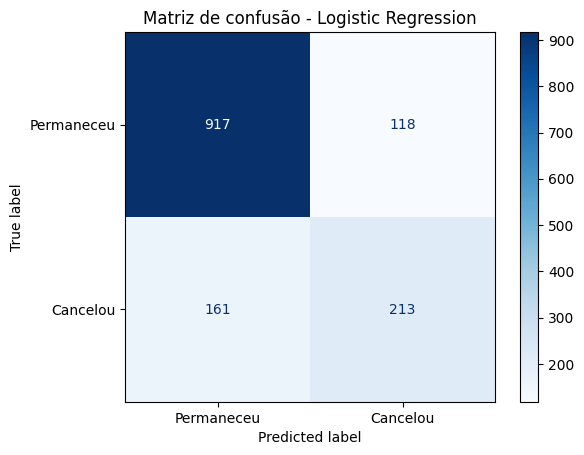

In [352]:
ConfusionMatrixDisplay.from_predictions(
  y_test,
  y_pred_logistic,
  display_labels=["Permaneceu", "Cancelou"],
  cmap="Blues"
)

plt.title("Matriz de confusão - Logistic Regression")
plt.show()

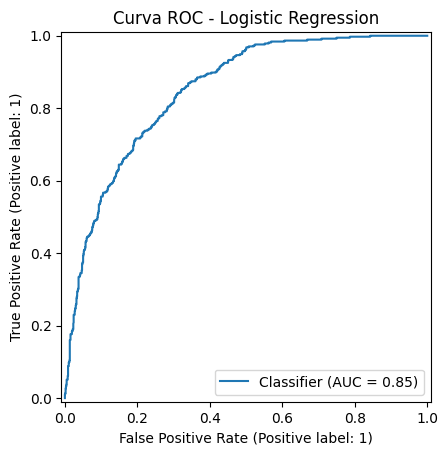

In [353]:
RocCurveDisplay.from_predictions(
  y_test,
  y_proba_logistic
)

plt.title("Curva ROC - Logistic Regression")
plt.show()

### Avaliação da Logistic Regression

A Logistic Regression apresentou **80,20% de acurácia** e **ROC-AUC de 84,89%**, indicando uma boa capacidade geral de separação entre clientes que permanecem e clientes que cancelam.

Entretanto, o principal ponto de atenção está no **Recall da classe de churn**, que foi de aproximadamente **56,95%**.

Isso significa que o modelo conseguiu identificar pouco mais da metade dos clientes que realmente cancelaram o serviço. Em um cenário de retenção, falsos negativos são particularmente importantes, pois representam clientes em risco que não seriam identificados previamente.

A Logistic Regression será utilizada como baseline para comparação com modelos mais complexos.

## 12. Random Forest

O Random Forest será utilizado como segundo modelo de classificação.

Por combinar diversas árvores de decisão, esse algoritmo é capaz de capturar relações não lineares e interações mais complexas entre as variáveis.

Seu desempenho será comparado com a Logistic Regression utilizando as mesmas métricas de avaliação.

In [354]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor), (
            "classifier",
            RandomForestClassifier(
                n_estimators=300, random_state=42, class_weight="balanced", n_jobs=-1
            )
        )
    ]
)

In [355]:
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Tenure Months', 'Monthly Charges', 'Total Charges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method'],
      dtype='object'))])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

In [356]:
y_pred_rf = random_forest_model.predict(X_test)

In [357]:
y_proba_rf = random_forest_model.predict_proba(X_test)[:, 1]

In [358]:
random_forest_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf),
    "Recall": recall_score(y_test, y_pred_rf),
    "F1-score": f1_score(y_test, y_pred_rf),
    "ROC-AUC": roc_auc_score(y_test, y_proba_rf),
}

random_forest_metrics

{'Accuracy': 0.7899219304471257,
 'Precision': 0.6291390728476821,
 'Recall': 0.5080213903743316,
 'F1-score': 0.5621301775147929,
 'ROC-AUC': np.float64(0.8347399829497015)}

In [359]:
print(classification_report(y_test, y_pred_rf, target_names=["Permaneceu", "Cancelou"]))

              precision    recall  f1-score   support

  Permaneceu       0.83      0.89      0.86      1035
    Cancelou       0.63      0.51      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



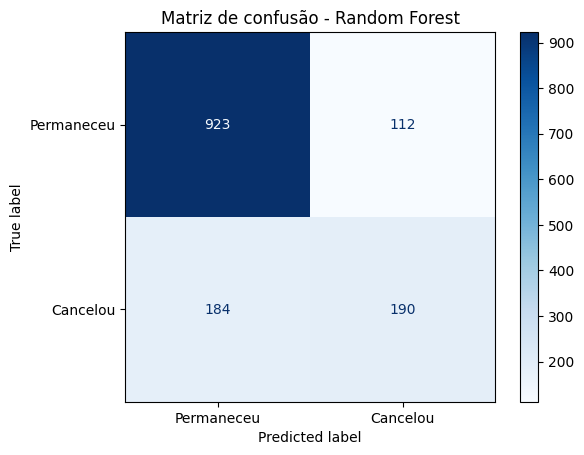

In [360]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf, display_labels=["Permaneceu", "Cancelou"], cmap="Blues"
)

plt.title("Matriz de confusão - Random Forest")
plt.show()

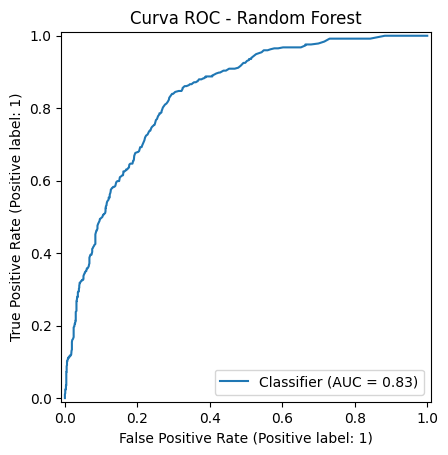

In [361]:
RocCurveDisplay.from_predictions(
  y_test,
  y_proba_rf
)

plt.title("Curva ROC - Random Forest")
plt.show()

### Avaliação do Random Forest

O Random Forest apresentou desempenho inferior à Logistic Regression na configuração inicial.

O modelo obteve aproximadamente:

- Accuracy: **78,99%**
- Precision: **62,91%**
- Recall: **50,80%**
- F1-score: **56,21%**
- ROC-AUC: **83,47%**

Apesar de utilizar `class_weight="balanced"` para considerar o desbalanceamento da variável alvo, o modelo apresentou menor capacidade de identificar clientes que realmente cancelaram o serviço.

O Recall da classe de churn foi de aproximadamente **50,80%**, inferior aos **56,95%** obtidos pela Logistic Regression.

Dessa forma, a Logistic Regression permanece como o melhor modelo entre os avaliados até o momento.

In [362]:
model_comparison = pd.DataFrame(
    {"Logistic Regression": logistic_metrics, "Random Forest": random_forest_metrics}
).T

model_comparison = model_comparison.mul(100).round(2)

model_comparison

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,80.20,64.35,56.95,60.43,84.89
Random Forest,78.99,62.91,50.80,56.21,83.47


## 13. Gradient Boosting

O Gradient Boosting será utilizado como terceiro modelo de classificação.

Diferentemente do Random Forest, que combina diversas árvores construídas de forma independente, o Gradient Boosting cria árvores sequencialmente, fazendo com que cada nova árvore tente corrigir os erros cometidos pelas anteriores.

O desempenho será comparado com a Logistic Regression e o Random Forest utilizando as mesmas métricas de avaliação.

In [363]:
gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(random_state=42)),
    ]
)

gradient_boosting_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Tenure Months', 'Monthly Charges', 'Total Charges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method'],
      dtype='object'))])),
                ('classifier', GradientBoostingClassifier(random_state=42))])

In [364]:
gradient_boosting_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['Tenure Months', 'Monthly Charges', 'Total Charges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service',
       'Multiple Lines', 'Internet Service', 'Online Security',
       'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV',
       'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method'],
      dtype='object'))])),
                ('classifier', GradientBoostingClassifier(random_state=42))])

In [365]:
y_pred_gb = gradient_boosting_model.predict(X_test)

y_proba_gb = gradient_boosting_model.predict_proba(X_test)[:, 1]

In [366]:
gradient_boosting_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_gb),
    "Precision": precision_score(y_test, y_pred_gb),
    "Recall": recall_score(y_test, y_pred_gb),
    "F1-score": f1_score(y_test, y_pred_gb),
    "ROC-AUC": roc_auc_score(y_test, y_proba_gb),
}

gradient_boosting_metrics

{'Accuracy': 0.7998580553584103,
 'Precision': 0.6493506493506493,
 'Recall': 0.5347593582887701,
 'F1-score': 0.5865102639296188,
 'ROC-AUC': np.float64(0.8522514143997519)}

In [367]:
print(classification_report(y_test, y_pred_gb, target_names=["Permaneceu", "Cancelou"]))

              precision    recall  f1-score   support

  Permaneceu       0.84      0.90      0.87      1035
    Cancelou       0.65      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



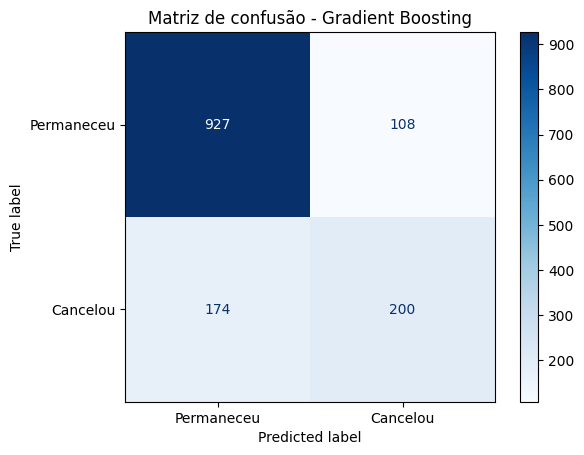

In [368]:
ConfusionMatrixDisplay.from_predictions(
  y_test,
  y_pred_gb,
  display_labels=["Permaneceu", "Cancelou"],
  cmap="Blues"
)

plt.title("Matriz de confusão - Gradient Boosting")
plt.show()

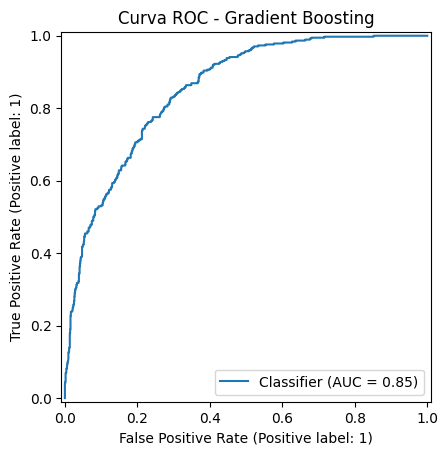

In [369]:
RocCurveDisplay.from_predictions(
  y_test,
  y_proba_gb
)

plt.title("Curva ROC - Gradient Boosting")
plt.show()

In [ ]:
model_comparison = pd.DataFrame(
    {
        "Logistic Regression": logistic_metrics,
        "Random Forest": random_forest_metrics,
        "Gradient Boosting": gradient_boosting_metrics,
    }
).T

model_comparison = model_comparison.mul(100).round(2)

model_comparison

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,80.20,64.35,56.95,60.43,84.89
Random Forest,78.99,62.91,50.80,56.21,83.47
Gradient Boosting,79.99,64.94,53.48,58.65,85.23


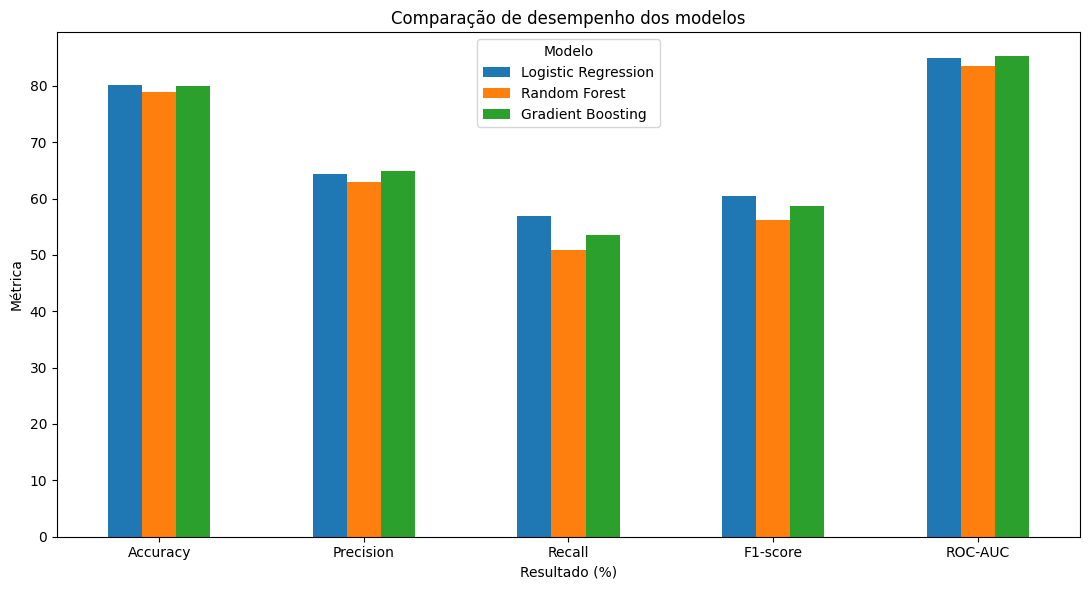

In [396]:
model_comparison_plot = model_comparison[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].T

model_comparison_plot.plot(kind="bar", figsize=(11, 6))

plt.title("Comparação de desempenho dos modelos")
plt.xlabel("Resultado (%)")
plt.ylabel("Métrica")

plt.xticks(rotation=0)

plt.legend(title="Modelo")

plt.tight_layout()

plt.savefig("../images/model_comparison.png", dpi=300, bbox_inches="tight")

plt.show()

### Comparação entre os modelos

Os três modelos apresentaram desempenho semelhante em termos de acurácia geral, porém diferenças importantes foram observadas nas métricas relacionadas à classe de churn.

A Logistic Regression apresentou o maior Recall da classe positiva, com aproximadamente **56,95%**, enquanto o Gradient Boosting apresentou **53,48%** e o Random Forest **50,80%**.

O Gradient Boosting obteve o maior ROC-AUC, com **85,23%**, indicando uma boa capacidade geral de separação entre as classes.

Entretanto, considerando o contexto de negócio, no qual deixar de identificar um cliente que realmente irá cancelar pode representar uma oportunidade de retenção perdida, a Logistic Regression permanece como o modelo de referência nesta etapa.

Na próxima etapa, será avaliado o impacto da alteração do limiar de decisão do modelo com o objetivo de aumentar o Recall dos clientes em risco de churn.

## 14. Ajuste do limiar de decisão

Por padrão, modelos de classificação binária utilizam um limiar de probabilidade de 0,50 para definir a classe prevista.

Entretanto, em problemas de churn, pode ser mais importante aumentar a capacidade de identificar clientes em risco, mesmo que isso resulte em mais falsos positivos.

Por esse motivo, diferentes valores de threshold serão avaliados para analisar o equilíbrio entre Precision e Recall.

In [371]:
thresholds = [0.50, 0.45, 0.40, 0.35, 0.30]

threshold_results = []

for threshold in thresholds:
    y_pred_threshold = (y_proba_logistic >= threshold).astype(int)

    threshold_results.append(
        {
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_test, y_pred_threshold),
            "Precision": precision_score(y_test, y_pred_threshold),
            "Recall": recall_score(y_test, y_pred_threshold),
            "F1-score": f1_score(y_test, y_pred_threshold),
        }
    )

threshold_comparison = pd.DataFrame(threshold_results)

threshold_comparison

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.50,0.801987,0.643505,0.569519,0.604255
1,0.45,0.792761,0.605670,0.628342,0.616798
2,0.40,0.783534,0.579310,0.673797,0.622991
3,0.35,0.775727,0.560669,0.716578,0.629108
4,0.30,0.758694,0.532443,0.745989,0.621381


In [372]:
threshold_comparison_percent = threshold_comparison.copy()

metrics_columns = ["Accuracy", "Precision", "Recall", "F1-score"]

threshold_comparison_percent[metrics_columns] = (
    threshold_comparison_percent[metrics_columns].mul(100).round(2)
)

threshold_comparison_percent

,Threshold,Accuracy,Precision,Recall,F1-score
0,0.50,80.20,64.35,56.95,60.43
1,0.45,79.28,60.57,62.83,61.68
2,0.40,78.35,57.93,67.38,62.30
3,0.35,77.57,56.07,71.66,62.91
4,0.30,75.87,53.24,74.60,62.14


### Escolha do threshold

A redução do limiar de decisão aumentou significativamente a capacidade do modelo de identificar clientes que realmente apresentam churn.

Com o threshold padrão de **0,50**, a Logistic Regression apresentou Recall de **56,95%**.

Ao reduzir o threshold para **0,35**, o Recall aumentou para **71,66%**, enquanto o F1-score também apresentou melhora, passando de **60,43%** para **62,91%**.

Apesar da redução da Accuracy para **77,57%** e da Precision para **56,07%**, esse comportamento pode ser aceitável em um cenário de retenção de clientes, pois permite identificar uma parcela maior dos clientes em risco.

Por apresentar o maior F1-score entre os thresholds avaliados e um ganho expressivo de Recall, o valor **0,35** foi escolhido como limiar de decisão para o modelo final.

In [373]:
final_threshold = 0.35

y_pred_final = (y_proba_logistic >= final_threshold).astype(int)

In [374]:
final_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred_final),
    "Precision": precision_score(y_test, y_pred_final),
    "Recall": recall_score(y_test, y_pred_final),
    "F1-score": f1_score(y_test, y_pred_final),
    "ROC-AUC": roc_auc_score(y_test, y_proba_logistic),
}

final_metrics

{'Accuracy': 0.7757274662881476,
 'Precision': 0.5606694560669456,
 'Recall': 0.7165775401069518,
 'F1-score': 0.6291079812206573,
 'ROC-AUC': np.float64(0.8488671885091322)}

In [375]:
print(
    classification_report(y_test, y_pred_final, target_names=["Permaneceu", "Cancelou"])
)

              precision    recall  f1-score   support

  Permaneceu       0.89      0.80      0.84      1035
    Cancelou       0.56      0.72      0.63       374

    accuracy                           0.78      1409
   macro avg       0.72      0.76      0.73      1409
weighted avg       0.80      0.78      0.78      1409



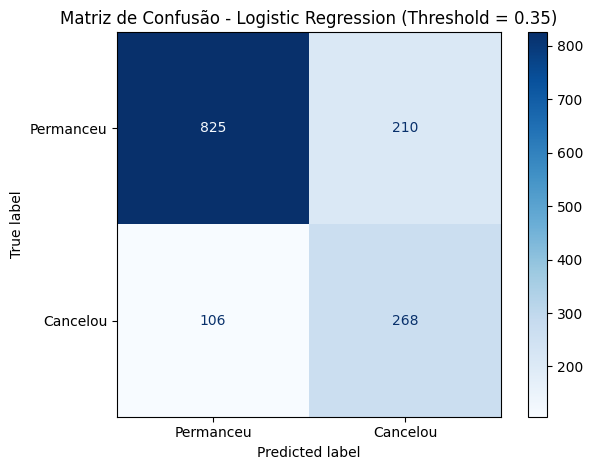

In [392]:
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_final, display_labels=["Permanceu", "Cancelou"], cmap="Blues"
)

plt.title("Matriz de Confusão - Logistic Regression (Threshold = 0.35)")

plt.tight_layout()

plt.savefig("../images/confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [377]:
threshold_model_comparison = pd.DataFrame({
    "Threshold 0.50": {
        "Accuracy": accuracy_score(y_test, y_pred_logistic),
        "Precision": precision_score(y_test, y_pred_logistic),
        "Recall": recall_score(y_test, y_pred_logistic),
        "F1-score": f1_score(y_test, y_pred_logistic)
    },
    "Threshold 0.35": {
        "Accuracy": accuracy_score(y_test, y_pred_final),
        "Precision": precision_score(y_test, y_pred_final),
        "Recall": recall_score(y_test, y_pred_final),
        "F1-score": f1_score(y_test, y_pred_final)
    }
}).T

threshold_model_comparison = (
    threshold_model_comparison
    .mul(100)
    .round(2)
)

threshold_model_comparison

,Accuracy,Precision,Recall,F1-score
Threshold 0.50,80.20,64.35,56.95,60.43
Threshold 0.35,77.57,56.07,71.66,62.91


### Interpretação da matriz de confusão

Com o threshold ajustado para **0,35**, o modelo apresentou os seguintes resultados no conjunto de teste:

- **825** clientes que permaneceram foram classificados corretamente;
- **268** clientes que cancelaram foram identificados corretamente;
- **210** clientes foram classificados como risco de churn, embora tenham permanecido;
- **106** clientes que realmente cancelaram não foram identificados pelo modelo.

Dos **374 clientes que realmente apresentaram churn**, o modelo conseguiu identificar **268**, correspondendo a um Recall de aproximadamente **71,66%**.

A redução do threshold aumentou a capacidade de detectar clientes em risco, ao custo de um aumento nos falsos positivos. Para um cenário de retenção, esse trade-off pode ser interessante, pois permite à empresa atuar preventivamente sobre uma parcela maior dos clientes com maior probabilidade de cancelamento.

## 15. Interpretação do modelo

Além da capacidade preditiva, é importante compreender quais características influenciam as previsões do modelo.

Como a Logistic Regression foi selecionada como modelo principal, seus coeficientes podem ser utilizados para analisar quais variáveis apresentam maior associação positiva ou negativa com o churn.

Coeficientes positivos estão associados ao aumento da probabilidade de churn, enquanto coeficientes negativos estão associados à redução dessa probabilidade.

In [381]:
feature_names = logistic_model.named_steps["preprocessor"].get_feature_names_out()

feature_names[:10]

array(['num__Tenure Months', 'num__Monthly Charges', 'num__Total Charges',
       'cat__Gender_Female', 'cat__Gender_Male', 'cat__Senior Citizen_No',
       'cat__Senior Citizen_Yes', 'cat__Partner_No', 'cat__Partner_Yes',
       'cat__Dependents_No'], dtype=object)

In [382]:
coefficients = logistic_model.named_steps["classifier"].coef_[0]

In [383]:
feature_importance = pd.DataFrame(
    {"Feature": feature_names, "Coefficient": coefficients}
)

feature_importance.head()

,Feature,Coefficient
0,num__Tenure Months,-1.270244
1,num__Monthly Charges,-0.497754
2,num__Total Charges,0.521700
3,cat__Gender_Female,-0.178396
4,cat__Gender_Male,-0.165549


In [384]:
top_positive = feature_importance.sort_values("Coefficient", ascending=False).head(10)

top_positive

,Feature,Coefficient
9,cat__Dependents_No,0.645479
37,cat__Contract_Month-to-month,0.563585
17,cat__Internet Service_Fiber optic,0.550165
2,num__Total Charges,0.521700
44,cat__Payment Method_Electronic check,0.188563
33,cat__Streaming TV_Yes,0.168955
36,cat__Streaming Movies_Yes,0.155942
19,cat__Online Security_No,0.132466
28,cat__Tech Support_No,0.114846
15,cat__Multiple Lines_Yes,0.081648


In [385]:
top_negative = feature_importance.sort_values("Coefficient", ascending=True).head(10)

top_negative

,Feature,Coefficient
0,num__Tenure Months,-1.270244
10,cat__Dependents_Yes,-0.989424
39,cat__Contract_Two year,-0.734672
16,cat__Internet Service_DSL,-0.608835
1,num__Monthly Charges,-0.497754
40,cat__Paperless Billing_No,-0.350410
7,cat__Partner_No,-0.317788
13,cat__Multiple Lines_No,-0.299459
20,cat__Online Security_No internet service,-0.285275
29,cat__Tech Support_No internet service,-0.285275


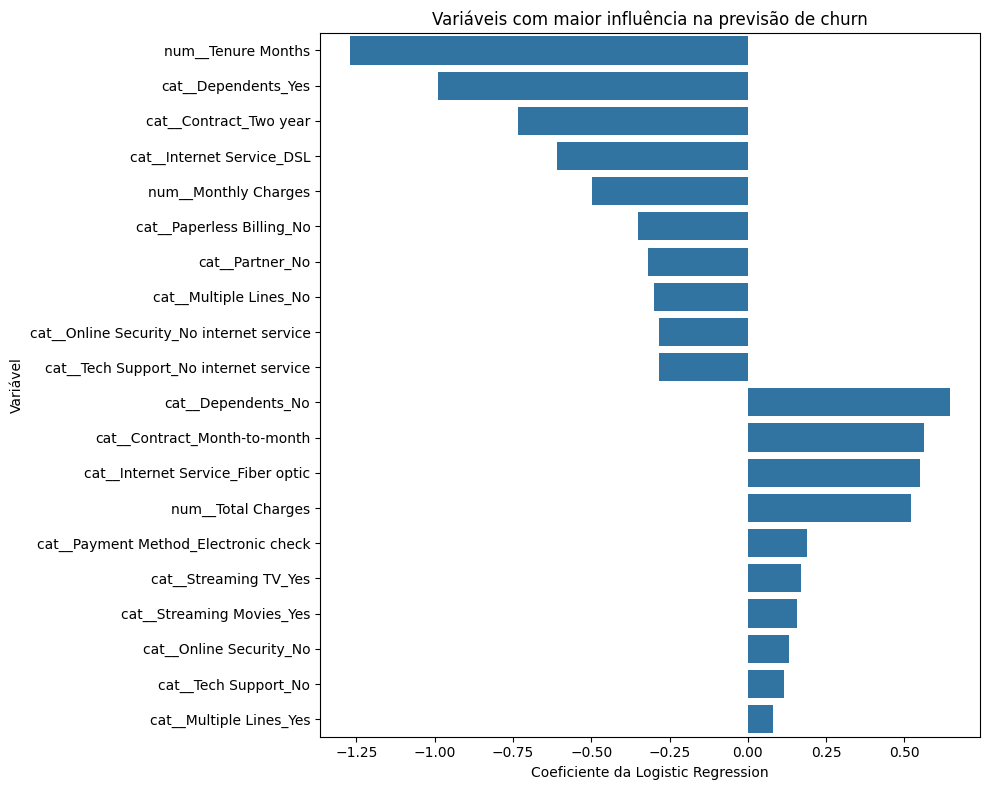

In [394]:
top_features = pd.concat([top_negative, top_positive])

plt.figure(figsize=(10, 8))

sns.barplot(data=top_features, x="Coefficient", y="Feature")

plt.title("Variáveis com maior influência na previsão de churn")

plt.xlabel("Coeficiente da Logistic Regression")
plt.ylabel("Variável")

plt.tight_layout()

plt.savefig("../images/features_importance.png", dpi=300, bbox_inches="tight")

plt.show()

### Interpretação dos coeficientes

Os coeficientes da Logistic Regression permitem identificar quais características estão mais associadas ao aumento ou à redução da probabilidade estimada de churn.

Entre as variáveis com associação positiva mais forte estão:

- clientes sem dependentes;
- contratos `Month-to-month`;
- utilização de internet por fibra óptica;
- maior valor acumulado em `Total Charges`;
- utilização de `Electronic check`;
- ausência de `Online Security`;
- ausência de `Tech Support`.

Por outro lado, algumas características apresentaram associação negativa com o churn, com destaque para:

- maior tempo de permanência (`Tenure Months`);
- presença de dependentes;
- contratos de dois anos;
- utilização de DSL.

O resultado relacionado ao tempo de permanência é especialmente relevante: `Tenure Months` apresentou um dos coeficientes negativos de maior magnitude, reforçando o padrão observado durante a análise exploratória de que clientes mais antigos tendem a apresentar menor incidência de churn.

Da mesma forma, contratos mensais e o uso de fibra óptica aparecem associados a maior probabilidade de churn tanto na análise exploratória quanto no modelo.

Esses resultados representam associações identificadas nos dados e não devem ser interpretados como relações causais.

### Observação sobre os coeficientes

Alguns coeficientes podem apresentar comportamento diferente das relações observadas individualmente durante a EDA.

Por exemplo, clientes com churn apresentaram cobranças mensais maiores na análise descritiva, porém `Monthly Charges` recebeu coeficiente negativo no modelo multivariado.

Isso ocorre porque a Logistic Regression estima o efeito de cada variável mantendo as demais constantes. Como algumas características possuem relação entre si, como tipo de serviço, contrato, tempo de permanência e valores cobrados, o sinal de um coeficiente pode diferir da relação observada de forma isolada.

Por esse motivo, os coeficientes são utilizados como ferramenta de interpretação do modelo e não como evidência de causalidade.

## 16. Recomendações de negócio

Com base nos padrões encontrados na análise exploratória e no modelo preditivo, algumas ações podem ser consideradas para estratégias de retenção.

### 1. Priorizar clientes com contratos mensais

Clientes com contrato `Month-to-month` apresentaram taxa de churn de **42,71%**, significativamente superior aos contratos de um e dois anos.

A empresa pode avaliar incentivos para migração para contratos de maior duração, como descontos progressivos, benefícios adicionais ou condições comerciais diferenciadas.

### 2. Criar ações de retenção nos primeiros meses

Clientes que cancelaram apresentaram tempo médio de permanência significativamente menor.

Estratégias de acompanhamento nos primeiros meses de relacionamento podem ajudar a identificar dificuldades rapidamente e aumentar o engajamento do cliente.

### 3. Investigar a experiência dos clientes de fibra óptica

Clientes com serviço `Fiber optic` apresentaram churn de **41,89%**, superior aos clientes com DSL.

Esse resultado sugere a necessidade de investigar fatores como qualidade do serviço, preço, estabilidade da conexão e percepção de valor.

### 4. Incentivar serviços de suporte

Clientes sem `Tech Support` e sem `Online Security` apresentaram taxas de churn superiores a 41%.

Ofertas combinadas, períodos gratuitos ou ações educativas sobre esses serviços podem contribuir para aumentar a percepção de valor e a retenção.

### 5. Avaliar clientes que utilizam Electronic Check

O método `Electronic check` apresentou a maior taxa de churn entre os métodos de pagamento analisados, com **45,29%**.

Esse grupo pode ser priorizado em análises adicionais e campanhas de migração para pagamentos automáticos.

### 6. Utilizar o modelo para priorização

O modelo final, com threshold de **0,35**, identificou aproximadamente **71,66% dos clientes que realmente apresentaram churn** no conjunto de teste.

A probabilidade estimada pelo modelo pode ser utilizada como um score de risco, permitindo que equipes de retenção priorizem clientes com maior probabilidade de cancelamento.

## 17. Salvando o modelo

O modelo final será salvo para permitir sua reutilização sem necessidade de novo treinamento.

In [390]:
joblib.dump(logistic_model, "../models/logistic_churn_model.joblib")

['../models/logistic_churn_model.joblib']